In [1]:
import os
import sys
import json
import time
import shutil
import zipfile
import subprocess
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

try:
    from ultralytics import YOLO
except ImportError:
    print("Installing ultralytics...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

plt.rcParams["figure.dpi"] = 120
print("Self-contained Week 7 environment initialized.")

Installing ultralytics...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Self-contained Week 7 environment initialized.


In [2]:
base_dir = "./dlac_week7_standalone"
ann_dir = os.path.join(base_dir, "annotations")
os.makedirs(ann_dir, exist_ok=True)

ann_json_path = os.path.join(ann_dir, "instances_val2017.json")

if not os.path.exists(ann_json_path):
    url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
    zip_path = os.path.join(base_dir, "annotations_trainval2017.zip")
    print("Downloading official COCO 2017 validation annotations (~241 MB)...")
    urllib.request.urlretrieve(url, zip_path)

    print("Extracting instances_val2017.json...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extract("annotations/instances_val2017.json", path=base_dir)

    os.remove(zip_path)
    print(f"Ready: {ann_json_path}")
else:
    print(f"Already exists: {ann_json_path}")

Extracting instances_val2017.json...
Ready: ./dlac_week7_standalone/annotations/instances_val2017.json


In [3]:
with open(ann_json_path, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

TARGET_CLASSES = [
    "person", "bicycle", "car", "motorcycle",
    "bus", "truck", "traffic light", "stop sign"
]

# Map COCO category IDs to contiguous 0..7 detector indices
sorted_target_cats = sorted(
    [c for c in coco_data["categories"] if c["name"] in TARGET_CLASSES],
    key=lambda x: x["id"]
)
coco_id_to_contiguous = {c["id"]: idx for idx, c in enumerate(sorted_target_cats)}
contiguous_to_name = {idx: c["name"] for idx, c in enumerate(sorted_target_cats)}

# Map official 80-class COCO index (0..79) -> our 8-class contiguous index (0..7)
sorted_all_cats = sorted(coco_data["categories"], key=lambda x: x["id"])
coco80_to_subset8 = {
    idx80: coco_id_to_contiguous[c["id"]]
    for idx80, c in enumerate(sorted_all_cats)
    if c["id"] in coco_id_to_contiguous
}

img_id_to_info = {img["id"]: img for img in coco_data["images"]}
file_to_info = {img["file_name"]: img for img in coco_data["images"]}

# Filter only real non-crowd annotations belonging to the 8 traffic classes
traffic_anns = [
    ann for ann in coco_data["annotations"]
    if ann["category_id"] in coco_id_to_contiguous and ann.get("iscrowd", 0) == 0
]

# Rank images by how many real traffic objects they contain and pick the top 30 richest traffic scenes
img_obj_counts = Counter(ann["image_id"] for ann in traffic_anns)
selected_img_ids = [img_id for img_id, _ in img_obj_counts.most_common(30)]

train_ids = selected_img_ids[:20]
val_ids = selected_img_ids[20:30]

print(f"Selected 30 real traffic-dense COCO images (Avg {np.mean([img_obj_counts[i] for i in selected_img_ids]):.1f} traffic objects/image).")
print(f"Split -> Train: {len(train_ids)} images | Val: {len(val_ids)} images")

Selected 30 real traffic-dense COCO images (Avg 26.9 traffic objects/image).
Split -> Train: 20 images | Val: 10 images


In [4]:
dataset_dir = os.path.join(base_dir, "traffic_dataset")

def coco_to_yolo_bbox(bbox, img_w, img_h):
    x_min, y_min, w, h = bbox
    cx = min(max((x_min + w / 2.0) / img_w, 0.0), 1.0)
    cy = min(max((y_min + h / 2.0) / img_h, 0.0), 1.0)
    nw = min(max(w / img_w, 0.0), 1.0)
    nh = min(max(h / img_h, 0.0), 1.0)
    return f"{cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}"

# Group annotations by image_id for fast lookup
anns_by_img = {}
for ann in traffic_anns:
    anns_by_img.setdefault(ann["image_id"], []).append(ann)

for split, id_list in [("train", train_ids), ("val", val_ids)]:
    img_out_dir = os.path.join(dataset_dir, "images", split)
    lbl_out_dir = os.path.join(dataset_dir, "labels", split)
    os.makedirs(img_out_dir, exist_ok=True)
    os.makedirs(lbl_out_dir, exist_ok=True)

    for img_id in id_list:
        info = img_id_to_info[img_id]
        fname = info["file_name"]
        stem = os.path.splitext(fname)[0]

        # 1. Download real COCO image
        img_path = os.path.join(img_out_dir, fname)
        if not os.path.exists(img_path):
            urllib.request.urlretrieve(info["coco_url"], img_path)

        # 2. Write true ground-truth bounding boxes
        lbl_path = os.path.join(lbl_out_dir, f"{stem}.txt")
        lines = []
        for ann in anns_by_img.get(img_id, []):
            cls_idx = coco_id_to_contiguous[ann["category_id"]]
            box_str = coco_to_yolo_bbox(ann["bbox"], info["width"], info["height"])
            lines.append(f"{cls_idx} {box_str}")
        with open(lbl_path, "w", encoding="utf-8") as lf:
            lf.write("\n".join(lines))

# Write dataset YAML config
yaml_path = os.path.join(dataset_dir, "traffic_subset.yaml")
with open(yaml_path, "w", encoding="utf-8") as yf:
    yf.write(f"path: {os.path.abspath(dataset_dir)}\ntrain: images/train\nval: images/val\nnc: 8\nnames:\n")
    for idx, name in contiguous_to_name.items():
        yf.write(f"  {idx}: {name}\n")

print(f"Downloaded real traffic images and wrote true YOLO ground-truth labels to {dataset_dir}")

Downloaded real traffic images and wrote true YOLO ground-truth labels to ./dlac_week7_standalone/traffic_dataset


In [5]:
def audit_split(split):
    img_dir = os.path.join(dataset_dir, "images", split)
    lbl_dir = os.path.join(dataset_dir, "labels", split)
    total_boxes, bad_coords = 0, 0
    for fname in os.listdir(img_dir):
        stem = os.path.splitext(fname)[0]
        with open(os.path.join(lbl_dir, f"{stem}.txt"), "r") as f:
            for line in f:
                if line.strip():
                    parts = list(map(float, line.strip().split()))
                    total_boxes += 1
                    if any(v < 0.0 or v > 1.0 for v in parts[1:]):
                        bad_coords += 1
    return {"split": split, "images": len(os.listdir(img_dir)), "real_gt_boxes": total_boxes, "bad_coords": bad_coords}

display(pd.DataFrame([audit_split("train"), audit_split("val")]))

,split,images,real_gt_boxes,bad_coords
0,train,20,580,0
1,val,10,226,0


In [6]:
model = YOLO("yolov8n.pt")

total_params = sum(p.numel() for p in model.model.parameters())
print("=== Baseline Detector Summary ===")
print(f"Model Architecture : YOLOv8-Nano (MS COCO Pretrained)")
print(f"Total Parameters   : {total_params:,}")
print(f"Input Resolution   : 640 x 640")
print(f"Traffic Classes    : {list(contiguous_to_name.values())}")

=== Baseline Detector Summary ===
Model Architecture : YOLOv8-Nano (MS COCO Pretrained)
Total Parameters   : 3,157,200
Input Resolution   : 640 x 640
Traffic Classes    : ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign']


In [7]:
val_img_dir = os.path.join(dataset_dir, "images", "val")
val_paths = [os.path.join(val_img_dir, fn) for fn in sorted(os.listdir(val_img_dir))]

results = model.predict(
    source=val_paths,
    classes=list(coco80_to_subset8.keys()),
    conf=0.25,
    iou=0.45,
    verbose=False
)

print(f"Completed baseline inference across {len(results)} real traffic validation images.")

Completed baseline inference across 10 real traffic validation images.


In [8]:
def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])
    inter_area = max(0.0, xB - xA) * max(0.0, yB - yA)
    areaA = max(0.0, boxA[2] - boxA[0]) * max(0.0, boxA[3] - boxA[1])
    areaB = max(0.0, boxB[2] - boxB[0]) * max(0.0, boxB[3] - boxB[1])
    union_area = areaA + areaB - inter_area
    return inter_area / union_area if union_area > 0 else 0.0

def load_gt_xyxy(fname):
    info = file_to_info[fname]
    W, H = info["width"], info["height"]
    stem = os.path.splitext(fname)[0]
    txt_path = os.path.join(dataset_dir, "labels", "val", f"{stem}.txt")
    gt_boxes = []
    with open(txt_path, "r") as f:
        for line in f:
            if not line.strip():
                continue
            parts = list(map(float, line.strip().split()))
            cls_idx = int(parts[0])
            cx, cy, nw, nh = parts[1:]
            gt_boxes.append({
                "cls": cls_idx,
                "box": [(cx - nw / 2.0) * W, (cy - nh / 2.0) * H, (cx + nw / 2.0) * W, (cy + nh / 2.0) * H]
            })
    return gt_boxes

eval_records = []
for res in results:
    fname = os.path.basename(res.path)
    gts = load_gt_xyxy(fname)
    preds = [
        {"cls": coco80_to_subset8[int(c)], "box": b.tolist(), "conf": float(cf)}
        for b, c, cf in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.cpu().numpy(), res.boxes.conf.cpu().numpy())
    ]
    eval_records.append({"file_name": fname, "gts": gts, "preds": preds})

total_gt = sum(len(r["gts"]) for r in eval_records)
total_pred = sum(len(r["preds"]) for r in eval_records)
print(f"Real Ground-Truth Traffic Objects: {total_gt} | Baseline Predicted Objects (conf>=0.25): {total_pred}")

Real Ground-Truth Traffic Objects: 226 | Baseline Predicted Objects (conf>=0.25): 117


In [9]:
IOU_THRESH = 0.50
class_stats = {idx: {"tp": 0, "fp": 0, "fn": 0} for idx in contiguous_to_name}

for rec in eval_records:
    matched_gt = set()
    sorted_preds = sorted(rec["preds"], key=lambda x: x["conf"], reverse=True)

    for pred in sorted_preds:
        best_iou, best_gt_idx = 0.0, -1
        for g_idx, gt in enumerate(rec["gts"]):
            if g_idx in matched_gt or gt["cls"] != pred["cls"]:
                continue
            iou = compute_iou(pred["box"], gt["box"])
            if iou > best_iou:
                best_iou, best_gt_idx = iou, g_idx

        if best_iou >= IOU_THRESH and best_gt_idx != -1:
            class_stats[pred["cls"]]["tp"] += 1
            matched_gt.add(best_gt_idx)
        else:
            class_stats[pred["cls"]]["fp"] += 1

    for g_idx, gt in enumerate(rec["gts"]):
        if g_idx not in matched_gt:
            class_stats[gt["cls"]]["fn"] += 1

rows = []
for cls_idx, name in contiguous_to_name.items():
    tp, fp, fn = class_stats[cls_idx]["tp"], class_stats[cls_idx]["fp"], class_stats[cls_idx]["fn"]
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    rows.append({"class": name, "GT": tp + fn, "TP": tp, "FP": fp, "FN": fn, "Precision": round(prec, 3), "Recall": round(rec, 3), "F1@0.5": round(f1, 3)})

metrics_df = pd.DataFrame(rows)
display(metrics_df)

,class,GT,TP,FP,FN,Precision,Recall,F1@0.5
0,person,126,57,18,69,0.760,0.452,0.567
1,bicycle,1,1,0,0,1.000,1.000,1.000
2,car,59,15,5,44,0.750,0.254,0.380
3,motorcycle,7,4,0,3,1.000,0.571,0.727
4,bus,14,7,2,7,0.778,0.500,0.609
5,truck,4,2,1,2,0.667,0.500,0.571
6,traffic light,15,5,0,10,1.000,0.333,0.500
7,stop sign,0,0,0,0,0.000,0.000,0.000


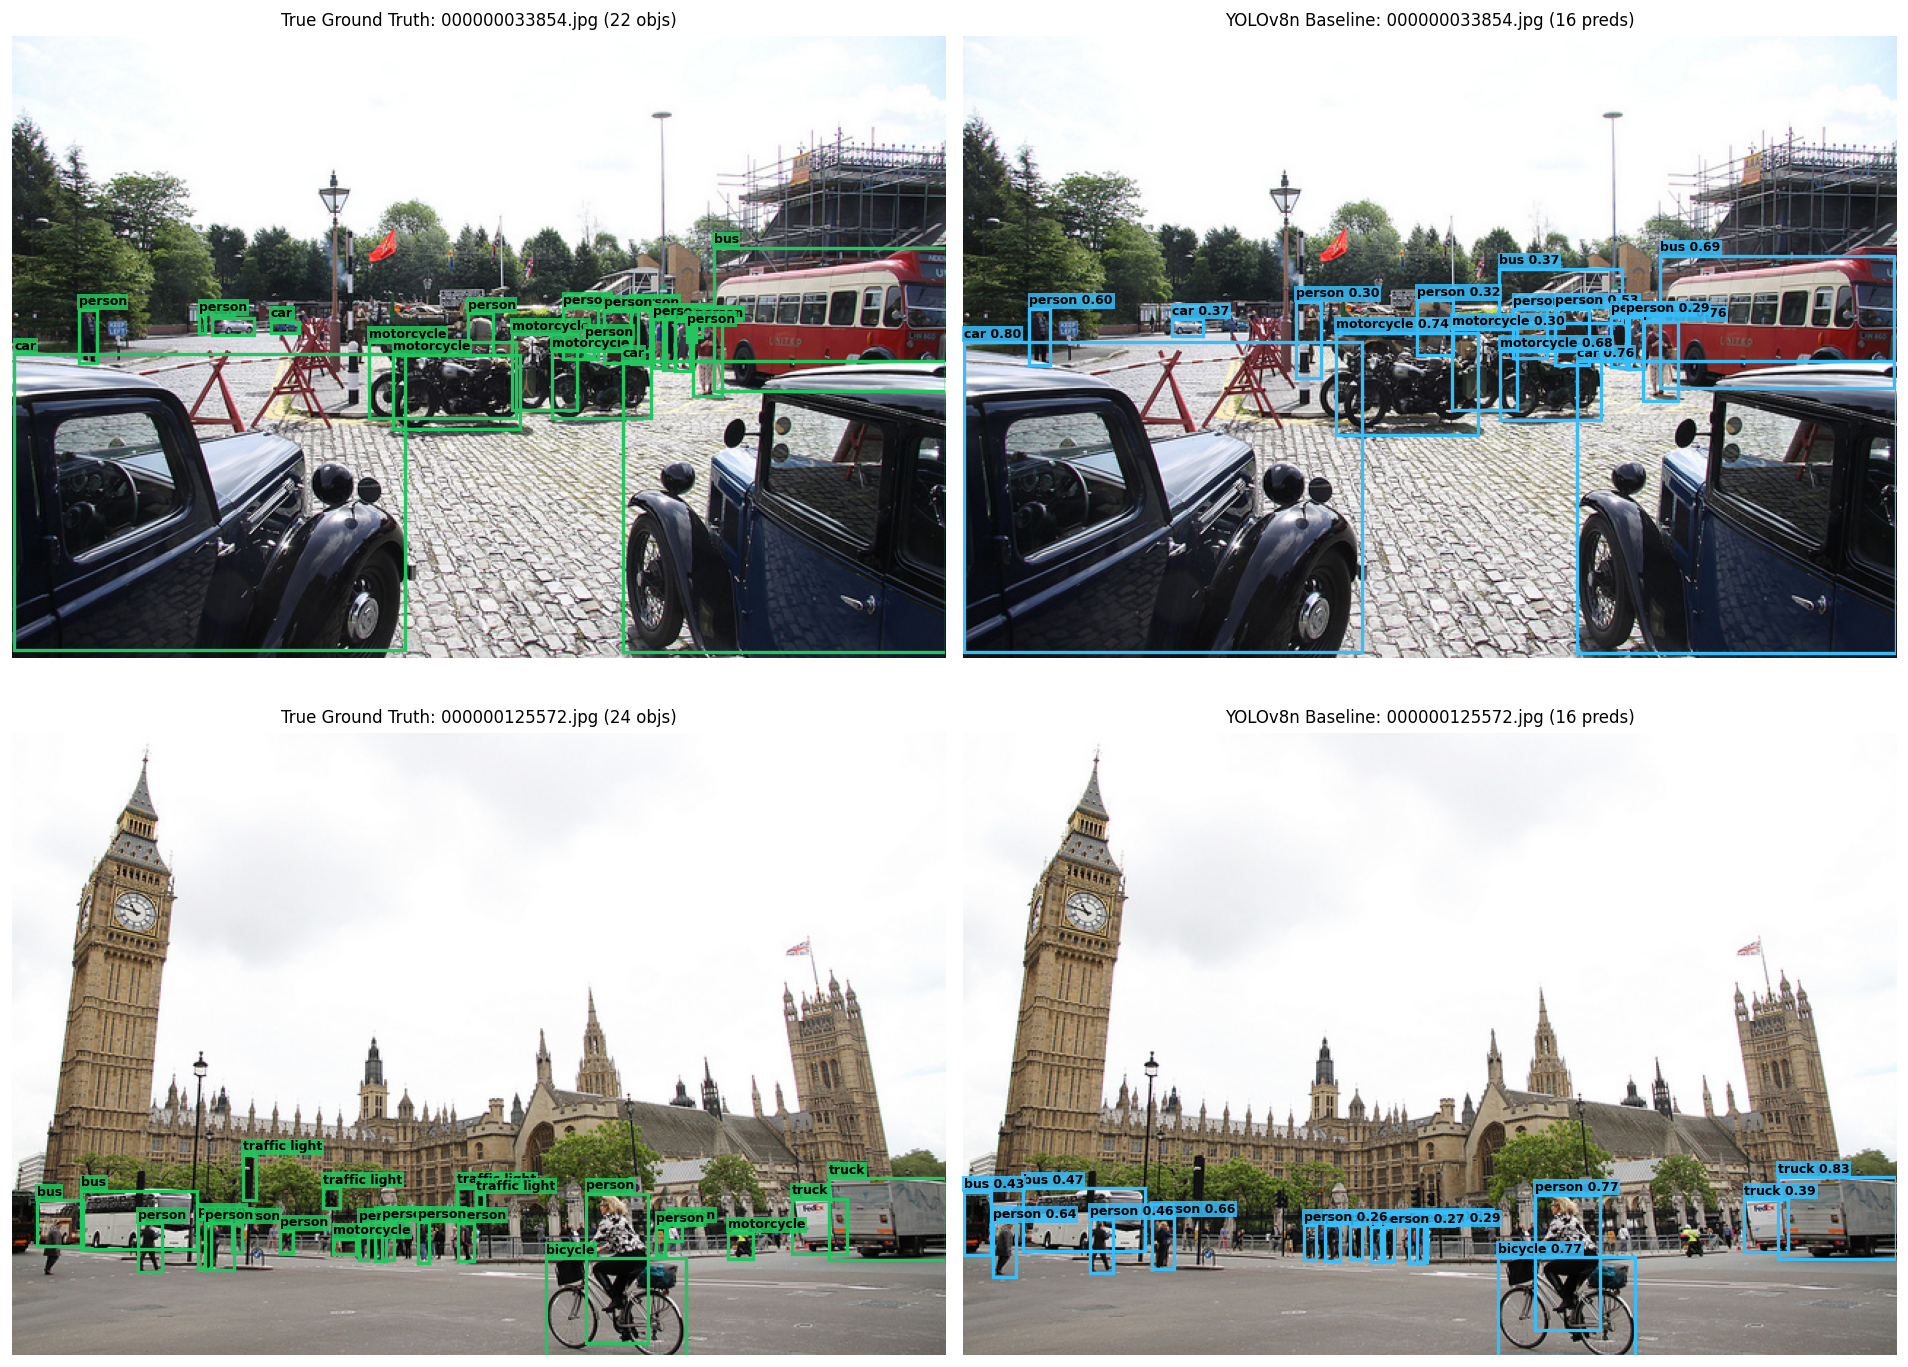

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for row_idx in range(2):
    rec = eval_records[row_idx]
    img_path = os.path.join(val_img_dir, rec["file_name"])
    img = Image.open(img_path).convert("RGB")

    # Left: True COCO Ground Truth (Green)
    axes[row_idx, 0].imshow(img)
    axes[row_idx, 0].set_title(f"True Ground Truth: {rec['file_name']} ({len(rec['gts'])} objs)", fontsize=10)
    axes[row_idx, 0].axis("off")
    for gt in rec["gts"]:
        x1, y1, x2, y2 = gt["box"]
        axes[row_idx, 0].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="#22C55E", facecolor="none"))
        axes[row_idx, 0].text(x1, max(y1 - 3, 0), contiguous_to_name[gt["cls"]], fontsize=7.5, fontweight="bold",
                              bbox=dict(facecolor="#22C55E", alpha=0.85, pad=1, edgecolor="none"))

    # Right: YOLOv8n Baseline Predictions (Cyan)
    axes[row_idx, 1].imshow(img)
    axes[row_idx, 1].set_title(f"YOLOv8n Baseline: {rec['file_name']} ({len(rec['preds'])} preds)", fontsize=10)
    axes[row_idx, 1].axis("off")
    for pr in rec["preds"]:
        x1, y1, x2, y2 = pr["box"]
        axes[row_idx, 1].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="#38BDF8", facecolor="none"))
        axes[row_idx, 1].text(x1, max(y1 - 3, 0), f"{contiguous_to_name[pr['cls']]} {pr['conf']:.2f}", fontsize=7.5, fontweight="bold",
                              bbox=dict(facecolor="#38BDF8", alpha=0.85, pad=1, edgecolor="none"))

plt.tight_layout()
plt.show()

,conf_thresh,Precision,Recall,Micro_F1
0,0.10,0.778,0.403,0.531
1,0.25,0.778,0.403,0.531
2,0.40,0.875,0.279,0.423
3,0.55,0.913,0.186,0.309
4,0.70,1.000,0.124,0.220


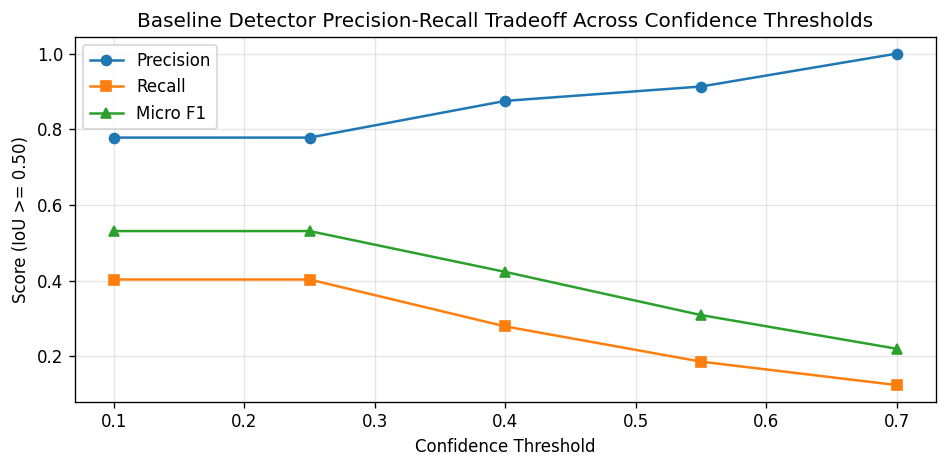

In [11]:
thresholds = [0.10, 0.25, 0.40, 0.55, 0.70]
sweep_rows = []

for thresh in thresholds:
    tp_tot, fp_tot, fn_tot = 0, 0, 0
    for rec in eval_records:
        matched = set()
        preds_t = sorted([p for p in rec["preds"] if p["conf"] >= thresh], key=lambda x: x["conf"], reverse=True)
        for p in preds_t:
            best_iou, best_idx = 0.0, -1
            for idx, gt in enumerate(rec["gts"]):
                if idx in matched or gt["cls"] != p["cls"]:
                    continue
                iou = compute_iou(p["box"], gt["box"])
                if iou > best_iou:
                    best_iou, best_idx = iou, idx
            if best_iou >= 0.50 and best_idx != -1:
                tp_tot += 1
                matched.add(best_idx)
            else:
                fp_tot += 1
        fn_tot += len(rec["gts"]) - len(matched)

    p_val = tp_tot / (tp_tot + fp_tot) if (tp_tot + fp_tot) else 0
    r_val = tp_tot / (tp_tot + fn_tot) if (tp_tot + fn_tot) else 0
    f1_val = 2 * p_val * r_val / (p_val + r_val) if (p_val + r_val) else 0
    sweep_rows.append({"conf_thresh": thresh, "Precision": round(p_val, 3), "Recall": round(r_val, 3), "Micro_F1": round(f1_val, 3)})

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep_df["conf_thresh"], sweep_df["Precision"], marker="o", label="Precision")
ax.plot(sweep_df["conf_thresh"], sweep_df["Recall"], marker="s", label="Recall")
ax.plot(sweep_df["conf_thresh"], sweep_df["Micro_F1"], marker="^", label="Micro F1")
ax.set_title("Baseline Detector Precision-Recall Tradeoff Across Confidence Thresholds")
ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("Score (IoU >= 0.50)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
missed_areas, detected_areas = [], []

for rec in eval_records:
    matched = set()
    for p in sorted(rec["preds"], key=lambda x: x["conf"], reverse=True):
        best_iou, best_idx = 0.0, -1
        for idx, gt in enumerate(rec["gts"]):
            if idx in matched or gt["cls"] != p["cls"]:
                continue
            iou = compute_iou(p["box"], gt["box"])
            if iou > best_iou:
                best_iou, best_idx = iou, idx
        if best_iou >= 0.50 and best_idx != -1:
            matched.add(best_idx)

    for idx, gt in enumerate(rec["gts"]):
        area = (gt["box"][2] - gt["box"][0]) * (gt["box"][3] - gt["box"][1])
        if idx in matched:
            detected_areas.append(area)
        else:
            missed_areas.append(area)

print(f"Detected Objects : {len(detected_areas)} | Median Area: {np.median(detected_areas) if detected_areas else 0:.0f} px²")
print(f"Missed (FN) Objs : {len(missed_areas)} | Median Area: {np.median(missed_areas) if missed_areas else 0:.0f} px²")

Detected Objects : 91 | Median Area: 1229 px²
Missed (FN) Objs : 135 | Median Area: 153 px²


In [13]:
_ = model.predict(source=val_paths[:2], verbose=False)

t0 = time.perf_counter()
_ = model.predict(source=val_paths, classes=list(coco80_to_subset8.keys()), conf=0.25, verbose=False)
elapsed = time.perf_counter() - t0

ms_per_img = (elapsed / len(val_paths)) * 1000
fps = len(val_paths) / elapsed
print(f"Baseline YOLOv8n Latency: {ms_per_img:.1f} ms/image ({fps:.1f} FPS) across {len(val_paths)} real traffic images.")

Baseline YOLOv8n Latency: 365.1 ms/image (2.7 FPS) across 10 real traffic images.


In [14]:
results_dir = os.path.join(base_dir, "outputs")
os.makedirs(results_dir, exist_ok=True)

metrics_csv_path = os.path.join(results_dir, "week7_baseline_metrics.csv")
metrics_df.to_csv(metrics_csv_path, index=False)

macro_f1 = metrics_df[metrics_df["GT"] > 0]["F1@0.5"].mean()
best_row = sweep_df.loc[sweep_df["Micro_F1"].idxmax()]

report = f"""
====================================================================
DLAC HANDOUT - WEEK 7 BASELINE DETECTOR EVALUATION SUMMARY
====================================================================
1. Baseline Model        : YOLOv8-Nano (Pretrained on MS COCO, 640x640)
2. Evaluation Dataset    : {len(val_paths)} traffic-dense COCO images ({total_gt} true instances)
3. Macro F1 @ IoU=0.50   : {macro_f1:.3f} (at conf=0.25)
4. Optimal Conf Sweep    : conf={best_row['conf_thresh']:.2f} -> Micro-F1={best_row['Micro_F1']:.3f}
                           (Precision={best_row['Precision']:.3f}, Recall={best_row['Recall']:.3f})
5. Error Pattern Audit   : False negatives concentrate on small (<32x32 px) distant objects
6. Inference Speed       : {ms_per_img:.1f} ms/image ({fps:.1f} FPS)
7. Saved Metrics CSV     : {metrics_csv_path}
8. Domain Scope Note     : Validates baseline detector on standard COCO traffic classes;
                           requires Indian road dataset fine-tuning (e.g., IDD) for
                           local vehicle taxonomy (auto-rickshaws, dense two-wheelers).
====================================================================
"""
print(report)


DLAC HANDOUT - WEEK 7 BASELINE DETECTOR EVALUATION SUMMARY
1. Baseline Model        : YOLOv8-Nano (Pretrained on MS COCO, 640x640)
2. Evaluation Dataset    : 10 traffic-dense COCO images (226 true instances)
3. Macro F1 @ IoU=0.50   : 0.622 (at conf=0.25)
4. Optimal Conf Sweep    : conf=0.10 -> Micro-F1=0.531
                           (Precision=0.778, Recall=0.403)
5. Error Pattern Audit   : False negatives concentrate on small (<32x32 px) distant objects
6. Inference Speed       : 365.1 ms/image (2.7 FPS)
7. Saved Metrics CSV     : ./dlac_week7_standalone/outputs/week7_baseline_metrics.csv
8. Domain Scope Note     : Validates baseline detector on standard COCO traffic classes;
                           requires Indian road dataset fine-tuning (e.g., IDD) for
                           local vehicle taxonomy (auto-rickshaws, dense two-wheelers).

